# 02 · AI4I 2020 — Modeling, Evaluation and Explainability

**Setup:** stratified 80/20 hold-out split (8,000 train / 2,000 test, seed 42). All model
selection uses 5-fold stratified CV on the 8,000 training rows. The test set is scored once,
at the end.

**Inputs:** Type (one-hot) + 5 sensor readings + 3 engineered features (ΔT, power,
strain), standardized. Failure subtypes and identifiers are excluded.

**Decision threshold:** chosen to maximize F1 on out-of-fold (OOF) training predictions.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as C
from src import visualization as V
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
FIG = C.FIGURES_DIR
import json, joblib
from src.models import ALGO_NAMES, STRATEGY_NAMES
from src.evaluate import compute_metrics, THRESHOLD_GRID
from src import explain as E
DS = "ai4i"; R = C.RESULTS_DIR; FIGD = FIG / ("ai4i" if DS == "ai4i" else "aps")
RUN_TRAINING = False   # True -> re-run the full pipeline (APS: ~2 h on 2 cores)
if RUN_TRAINING:
    import subprocess; subprocess.run([sys.executable, "-m", "src.train", "--dataset", DS], cwd=ROOT, check=True)
strat = pd.read_csv(R / f"{DS}_strategy_cv.csv"); tuned = pd.read_csv(R / f"{DS}_tuned_cv.csv")
test = pd.read_csv(R / f"{DS}_test_results.csv"); proba = dict(np.load(R / f"{DS}_test_proba.npz"))
y_te = np.load(R / f"{DS}_y_test.npy"); best = json.loads((R / f"{DS}_best_model.json").read_text())
oof_t = dict(np.load(R / f"{DS}_oof_tuned.npz"))
name = lambda a: ALGO_NAMES[a]

## 2. Baseline models (default hyperparameters, no imbalance handling, threshold 0.5)

In [2]:
cols = ["algo","cv_accuracy","cv_precision","cv_recall","cv_f1","cv_roc_auc","cv_pr_auc","cv_fpr","cv_fnr","fit_time_s","predict_ms_per_1k"]
base = strat[strat.strategy=="none"][cols].assign(algo=lambda d: d.algo.map(ALGO_NAMES))
display(base.round(3))
print("accuracy of the trivial 'never fails' rule:", round(1 - y_te.mean(), 4), "(on test) -> accuracy alone is uninformative")

,algo,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc,cv_fpr,cv_fnr,fit_time_s,predict_ms_per_1k
0,Logistic Regression,0.972,0.774,0.251,0.378,0.914,0.501,0.003,0.749,0.032,5.110
4,KNN,0.974,0.754,0.332,0.461,0.867,0.520,0.004,0.668,0.025,35.032
7,Decision Tree,0.988,0.823,0.830,0.826,0.912,0.689,0.006,0.170,0.042,4.644
11,Random Forest,0.993,0.974,0.819,0.889,0.970,0.896,0.001,0.181,0.961,25.169
15,Gradient Boosting,0.993,0.958,0.830,0.889,0.982,0.910,0.001,0.170,1.225,4.983


accuracy of the trivial 'never fails' rule: 0.966 (on test) -> accuracy alone is uninformative


## 3. Class-imbalance strategies (5-fold CV, default hyperparameters)

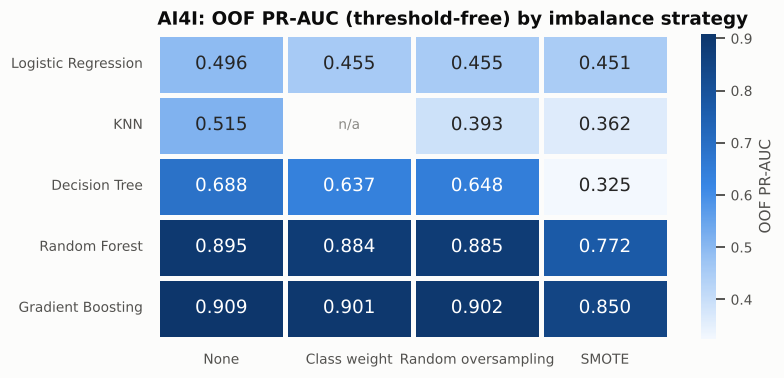

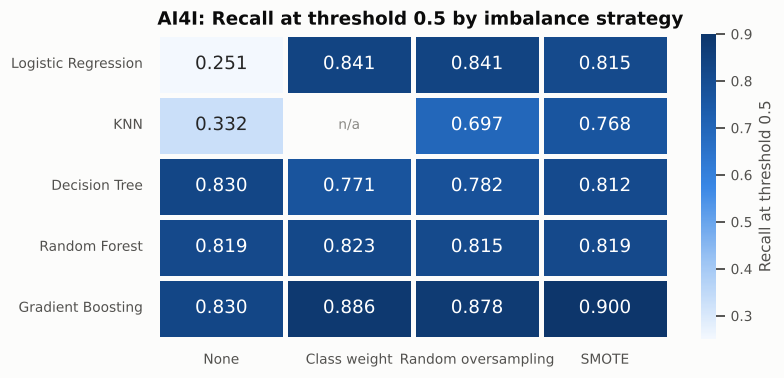

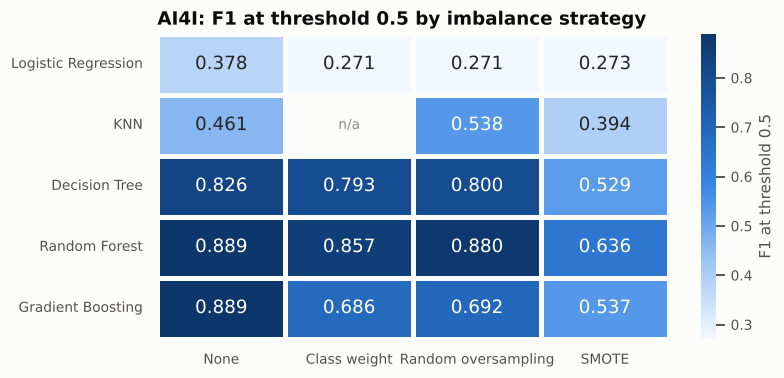

,algo,strategy,oof_pr_auc,cv_precision,cv_recall,cv_f1,cv_fpr,fit_time_s
0,logreg,none,0.496,0.774,0.251,0.378,0.003,0.032
1,logreg,class_weight,0.455,0.162,0.841,0.271,0.153,0.038
2,logreg,ros,0.455,0.162,0.841,0.271,0.153,0.055
3,logreg,smote,0.451,0.164,0.815,0.273,0.146,0.148
4,knn,none,0.515,0.754,0.332,0.461,0.004,0.025
5,knn,ros,0.393,0.439,0.697,0.538,0.031,0.044
6,knn,smote,0.362,0.266,0.768,0.394,0.075,0.124
7,dtree,none,0.688,0.823,0.830,0.826,0.006,0.042
8,dtree,class_weight,0.637,0.823,0.771,0.793,0.006,0.039
9,dtree,ros,0.648,0.820,0.782,0.800,0.006,0.061


In [3]:
for metric, lab, fn in [("oof_pr_auc","OOF PR-AUC (threshold-free)","08"),("cv_recall","Recall at threshold 0.5","09"),("cv_f1","F1 at threshold 0.5","10")]:
    pv = strat.pivot(index="algo", columns="strategy", values=metric).reindex(index=list(ALGO_NAMES), columns=list(STRATEGY_NAMES))
    pv.index = pv.index.map(ALGO_NAMES); pv.columns = pv.columns.map(STRATEGY_NAMES)
    fig = V.strategy_heatmap(pv, f"{DS.upper()}: {lab} by imbalance strategy", cbar_label=lab.split(" (")[0])
    V.save(fig, FIGD / f"{fn}_imbalance_{metric}.png"); plt.show()
display(strat[["algo","strategy","oof_pr_auc","cv_precision","cv_recall","cv_f1","cv_fpr","fit_time_s"]].round(3))

## 4. Hyperparameter tuning (RandomizedSearchCV, scored on average precision)

,algo,strategy,params,search_n_iter,search_folds,search_best_ap,search_time_s,oof_pr_auc,threshold,oof_precision@thr,oof_recall@thr,oof_f1@thr,oof_fp@thr,oof_fn@thr,oof_cost@thr
0,Logistic Regression,none,"{""clf__C"": 0.9846738873614566}",15,5,0.5004,7.6754,0.4958,0.24,0.5202,0.4760,0.4971,119,142,72190
1,KNN,none,"{""clf__weights"": ""distance"", ""clf__p"": 1, ""clf...",20,5,0.6953,9.9700,0.6913,0.19,0.6596,0.6937,0.6763,97,83,42470
2,Decision Tree,none,"{""clf__min_samples_leaf"": 20, ""clf__max_depth""...",30,5,0.8826,7.4280,0.8938,0.41,0.9515,0.7970,0.8675,11,55,27610
3,Random Forest,none,"{""clf__n_estimators"": 300, ""clf__min_samples_l...",20,5,0.9013,187.5306,0.9007,0.42,0.9534,0.8303,0.8876,11,46,23110
4,Gradient Boosting,none,"{""clf__learning_rate"": 0.01855998084649059, ""c...",25,5,0.9097,403.4820,0.9087,0.58,0.9737,0.8192,0.8898,6,49,24560


,algo,baseline,tuned (best strategy),gain
0,Logistic Regression,0.4958,0.4958,-0.0000
1,KNN,0.5149,0.6913,0.1764
2,Decision Tree,0.6875,0.8938,0.2062
3,Random Forest,0.8953,0.9007,0.0054
4,Gradient Boosting,0.9088,0.9087,-0.0001


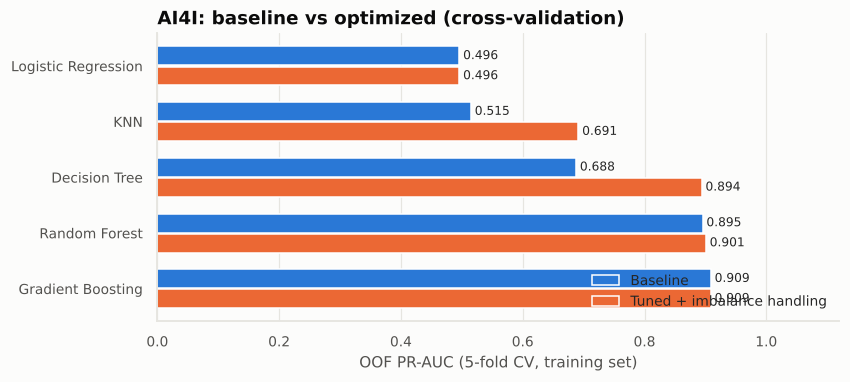

In [4]:
tcols = ["algo","strategy","params","search_n_iter","search_folds","search_best_ap","search_time_s","oof_pr_auc","threshold","oof_precision@thr","oof_recall@thr","oof_f1@thr","oof_fp@thr","oof_fn@thr","oof_cost@thr"]
display(tuned[tcols].assign(algo=lambda d: d.algo.map(ALGO_NAMES)).round(4))
cmp = strat[strat.strategy=="none"][["algo","oof_pr_auc"]].rename(columns={"oof_pr_auc":"baseline"}).merge(
      tuned[["algo","oof_pr_auc"]].rename(columns={"oof_pr_auc":"tuned (best strategy)"}), on="algo")
display(cmp.assign(gain=lambda d: d["tuned (best strategy)"]-d.baseline, algo=lambda d: d.algo.map(ALGO_NAMES)).round(4))
fig, ax = plt.subplots(figsize=(8,3.4)); yy = np.arange(len(cmp))
ax.barh(yy-0.18, cmp.baseline, 0.34, color=V.SERIES[0], label="Baseline"); ax.barh(yy+0.18, cmp["tuned (best strategy)"], 0.34, color=V.SERIES[1], label="Tuned + imbalance handling")
for i,(b,t) in enumerate(zip(cmp.baseline, cmp["tuned (best strategy)"])): ax.text(b, i-0.18, f" {b:.3f}", va="center", fontsize=8); ax.text(t, i+0.18, f" {t:.3f}", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(cmp.algo.map(ALGO_NAMES)); ax.invert_yaxis(); ax.set_xlim(0,1.12); ax.set_xlabel("OOF PR-AUC (5-fold CV, training set)")
ax.set_title("AI4I: baseline vs optimized (cross-validation)"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
V.save(fig, FIGD / "11_baseline_vs_tuned_cv.png"); plt.show()

## 5. Final evaluation on the held-out test set (scored once)

,model,threshold_rule,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,fpr,fnr,fp,fn
0,logreg_baseline,default_0.5,0.50,0.9675,0.5714,0.1765,0.2697,0.9255,0.4638,0.0047,0.8235,9,56
1,logreg_tuned,default_0.5,0.50,0.9675,0.5714,0.1765,0.2697,0.9257,0.4639,0.0047,0.8235,9,56
2,logreg_tuned,oof_f1,0.24,0.9675,0.5246,0.4706,0.4961,0.9257,0.4639,0.0150,0.5294,29,36
3,knn_baseline,default_0.5,0.50,0.9750,0.8750,0.3088,0.4565,0.8827,0.5311,0.0016,0.6912,3,47
4,knn_tuned,default_0.5,0.50,0.9705,1.0000,0.1324,0.2338,0.9312,0.6845,0.0000,0.8676,0,59
5,knn_tuned,oof_f1,0.19,0.9755,0.6338,0.6618,0.6475,0.9312,0.6845,0.0135,0.3382,26,23
6,dtree_baseline,default_0.5,0.50,0.9860,0.7857,0.8088,0.7971,0.9005,0.6420,0.0078,0.1912,15,13
7,dtree_tuned,default_0.5,0.50,0.9905,0.9455,0.7647,0.8455,0.9705,0.8701,0.0016,0.2353,3,16
8,dtree_tuned,oof_f1,0.41,0.9905,0.9455,0.7647,0.8455,0.9705,0.8701,0.0016,0.2353,3,16
9,rf_baseline,default_0.5,0.50,0.9920,0.9643,0.7941,0.8710,0.9673,0.8860,0.0010,0.2059,2,14


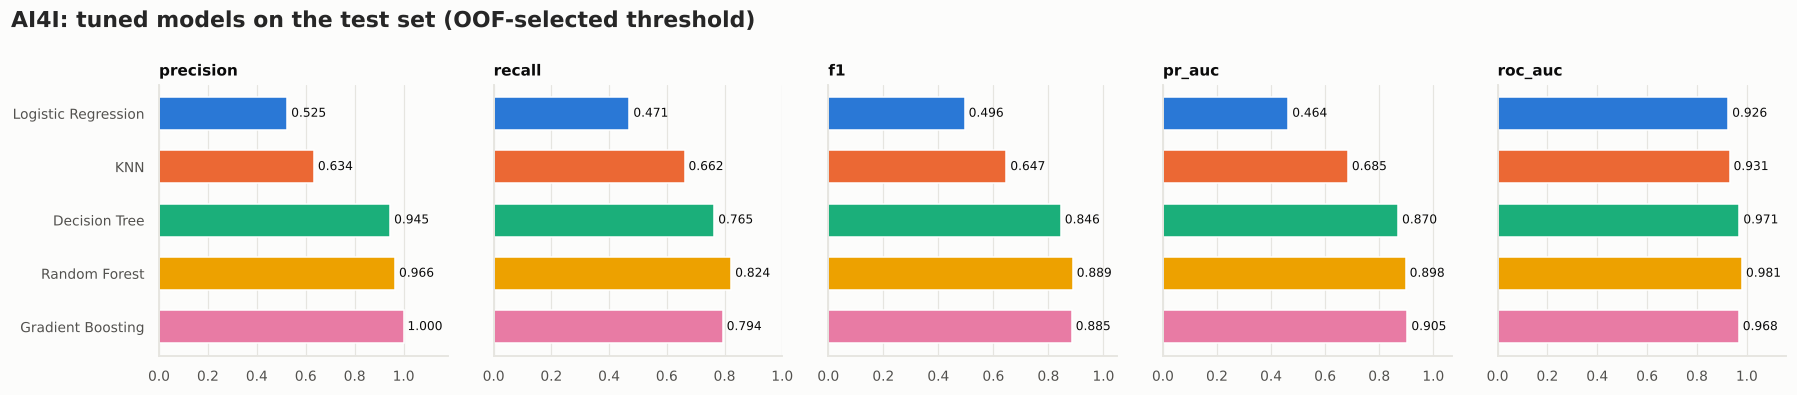

In [5]:
tt = test.copy(); tt["algo"] = tt.model.str.split("_").str[0]
show = ["model","threshold_rule","threshold","accuracy","precision","recall","f1","roc_auc","pr_auc","fpr","fnr","fp","fn"] + (["cost"] if DS == "aps" else [])
display(tt[show].round(4))
final = tt[tt.threshold_rule == "oof_f1"].copy()
fig = V.metric_bars(final, ["precision","recall","f1","pr_auc","roc_auc"], "AI4I: tuned models on the test set (OOF-selected threshold)")
V.save(fig, FIGD / "12_test_model_comparison.png"); plt.show()

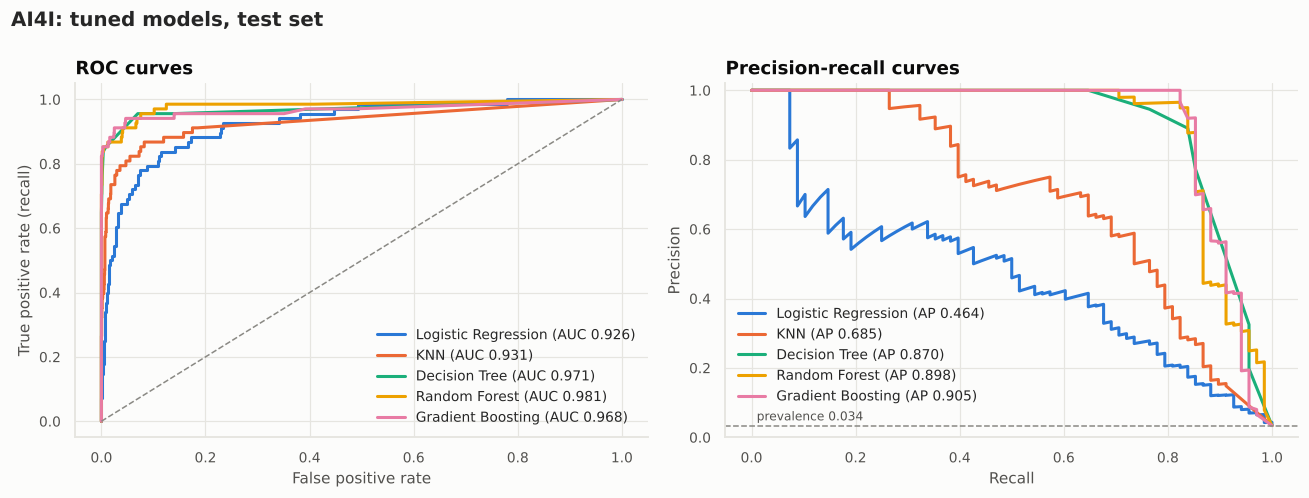

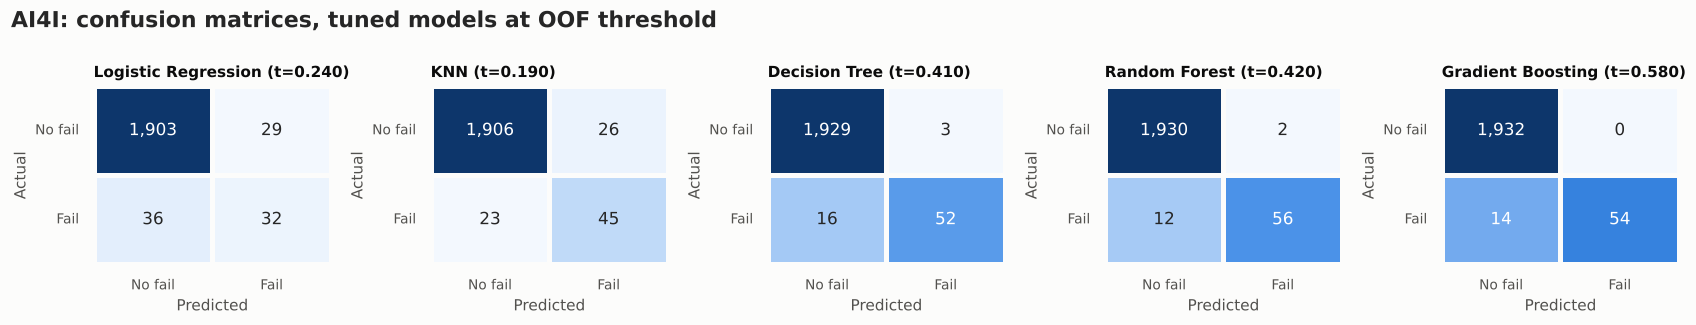

In [6]:
tuned_keys = [f"{a}_tuned" for a in ALGO_NAMES]
V.save(V.roc_pr_curves(y_te, {k: proba[k] for k in tuned_keys}, f"{DS.upper()}: tuned models, test set"), FIGD / "13_roc_pr_curves.png"); plt.show()
thr = {a: float(tuned.set_index("algo").loc[a, "threshold"]) for a in ALGO_NAMES}
preds = {f"{name(a)} (t={thr[a]:.3f})": (proba[f"{a}_tuned"] >= thr[a]).astype(int) for a in ALGO_NAMES}
V.save(V.confusion_grid(y_te, preds, f"{DS.upper()}: confusion matrices, tuned models at OOF threshold"), FIGD / "14_confusion_matrices.png"); plt.show()

### 5b. Which failures are missed? (test set, best model, by failure subtype)

In [7]:
from src.data_loader import load_ai4i
from src.preprocessing import ai4i_split
_, X_te_idx, _, _ = ai4i_split()
raw = load_ai4i().loc[X_te_idx.index]
pb = proba[f"{best['algo']}_tuned"] >= best["threshold"]
fails = raw[raw[C.AI4I_TARGET] == 1].copy(); fails["detected"] = pb[raw[C.AI4I_TARGET].to_numpy() == 1]
def mode(r):
    m = [s for s in C.AI4I_LEAKAGE_COLS if r[s] == 1]; return "+".join(m) if m else "no subtype flagged"
fails["mode"] = fails.apply(mode, axis=1)
display(fails.groupby("mode").detected.agg(failures="size", detected="sum").assign(recall=lambda d: (d.detected/d.failures).round(3)).sort_values("failures", ascending=False))

,failures,detected,recall
mode,,,
HDF,28,25,0.893
OSF,15,15,1.000
PWF,12,12,1.000
TWF,9,0,0.000
no subtype flagged,2,0,0.000
HDF+PWF,1,1,1.000
TWF+OSF,1,1,1.000


### 5c. Feature-engineering ablation (5-fold CV, training set)

In [8]:
abl = pd.read_csv(R / "ai4i_feature_ablation.csv"); display(abl.assign(algo=abl.algo.map(ALGO_NAMES)).round(3))

,algo,engineered_features,oof_pr_auc,cv_pr_auc_std,oof_f1@best_thr,oof_recall@best_thr
0,Logistic Regression,False,0.459,0.032,0.497,0.535
1,Logistic Regression,True,0.496,0.031,0.497,0.476
2,Decision Tree,False,0.483,0.066,0.687,0.672
3,Decision Tree,True,0.688,0.042,0.826,0.830
4,Random Forest,False,0.760,0.025,0.738,0.742
5,Random Forest,True,0.895,0.024,0.892,0.827
6,Gradient Boosting,False,0.782,0.030,0.753,0.697
7,Gradient Boosting,True,0.909,0.021,0.890,0.849


## 6. Trade-off: false alarms vs missed failures

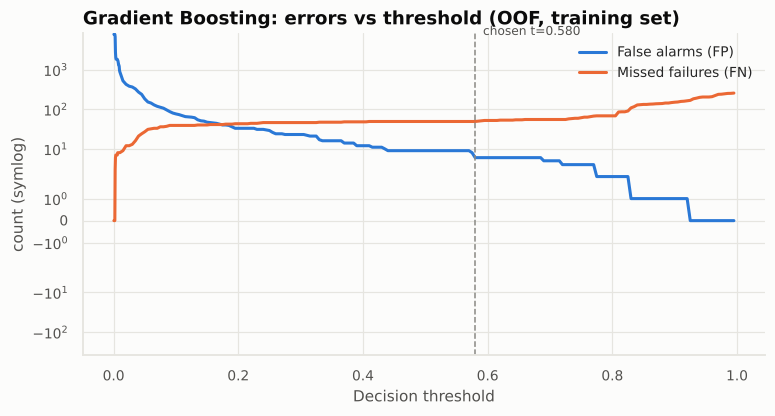

,threshold,precision,recall,f1,fp,fn
27,0.05,0.573,0.900,0.700,182,27
37,0.10,0.753,0.856,0.801,76,39
57,0.20,0.874,0.841,0.857,33,43
77,0.30,0.907,0.830,0.867,23,46
117,0.50,0.961,0.819,0.884,9,49
133,0.58,0.974,0.819,0.890,6,49
157,0.70,0.977,0.797,0.878,5,55


In [9]:
a = best["algo"]; p_oof = oof_t[a]
from src.preprocessing import ai4i_split, aps_xy
y_tr = (ai4i_split()[2] if DS == "ai4i" else aps_xy()[1]).to_numpy()
rows = [compute_metrics(y_tr, p_oof, t) for t in THRESHOLD_GRID]
tr_df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8,3.8))
ax.plot(tr_df.threshold, tr_df.fp, color=V.SERIES[0], label="False alarms (FP)"); ax.plot(tr_df.threshold, tr_df.fn, color=V.SERIES[1], label="Missed failures (FN)")
ax.axvline(best["threshold"], color=V.MUTED, ls="--", lw=1); ax.text(best["threshold"], ax.get_ylim()[1]*0.92, f"  chosen t={best['threshold']:.3f}", fontsize=8, color=V.INK2)
ax.set_yscale("symlog"); ax.set(xlabel="Decision threshold", ylabel="count (symlog)", title=f"{name(a)}: errors vs threshold (OOF, training set)"); ax.legend()
V.save(fig, FIGD / "15_threshold_tradeoff.png"); plt.show()
if DS == "aps":
    fig, ax = plt.subplots(figsize=(8,3.4)); ax.plot(tr_df.threshold, tr_df.cost, color=V.SERIES[0])
    ax.axvline(best["threshold"], color=V.MUTED, ls="--", lw=1); ax.set_xscale("log"); ax.set(xlabel="Decision threshold (log scale)", ylabel="10·FP + 500·FN", title="Scania cost vs threshold (OOF, best model)")
    V.save(fig, FIGD / "16_cost_vs_threshold.png"); plt.show()
display(tr_df.loc[tr_df.threshold.isin([0.05,0.1,0.2,0.3,0.5,0.7, best['threshold']]), ["threshold","precision","recall","f1","fp","fn"] + (["cost"] if DS == "aps" else [])].round(3))

## 7. Training and inference time

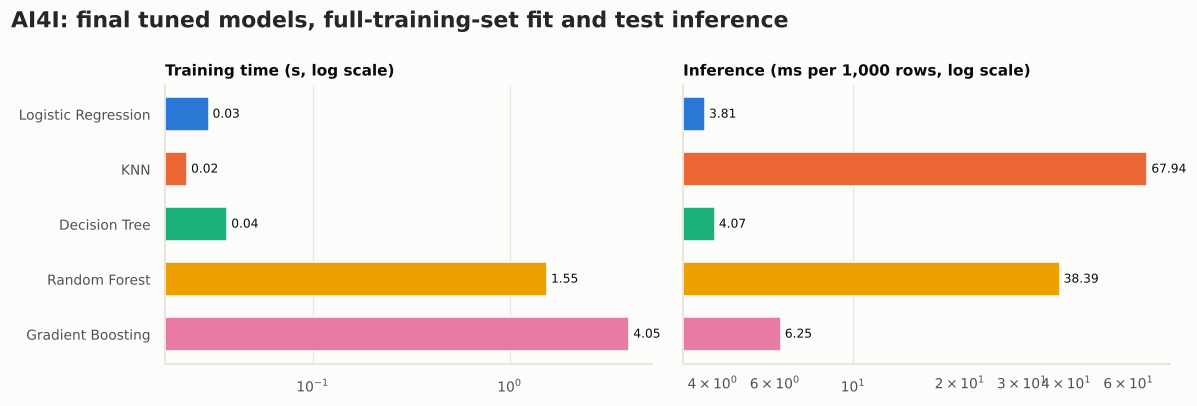

,model,fit_time_s,predict_ms_per_1k
0,logreg_baseline,0.032,4.147
1,logreg_tuned,0.030,3.813
3,knn_baseline,0.022,20.958
4,knn_tuned,0.023,67.938
6,dtree_baseline,0.047,4.033
7,dtree_tuned,0.037,4.065
9,rf_baseline,0.559,15.188
10,rf_tuned,1.549,38.389
12,gb_baseline,1.374,4.712
13,gb_tuned,4.050,6.245


In [10]:
tm = final[["algo","fit_time_s","predict_ms_per_1k"]]
V.save(V.time_bars(tm, "AI4I: final tuned models, full-training-set fit and test inference"), FIGD / "17_time_comparison.png"); plt.show()
display(tt.drop_duplicates("model")[["model","fit_time_s","predict_ms_per_1k"]].round(3))

## 8. Explainability

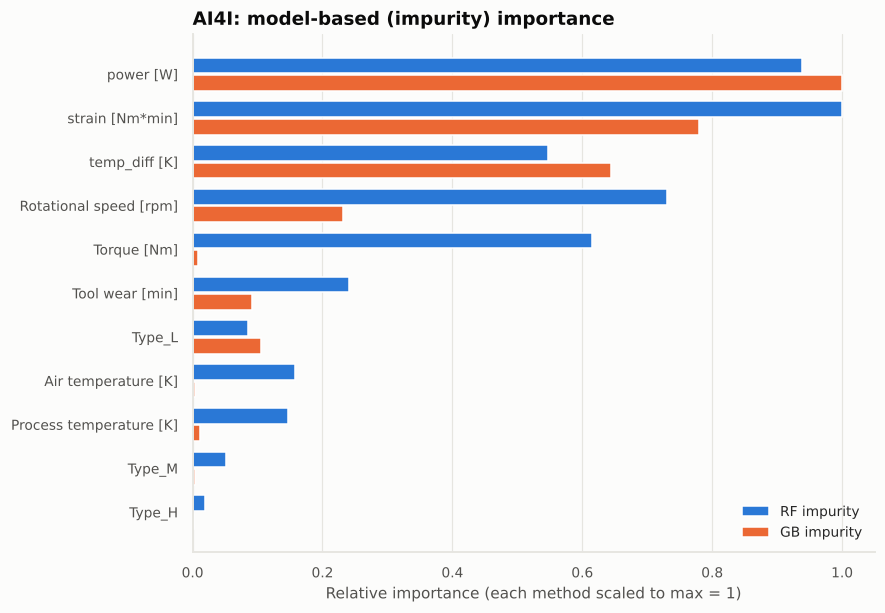

,RF impurity,GB impurity
strain [Nm*min],1.000,0.780
power [W],0.938,1.000
Rotational speed [rpm],0.730,0.232
Torque [Nm],0.614,0.009
temp_diff [K],0.548,0.644
Tool wear [min],0.241,0.091
Air temperature [K],0.158,0.004
Process temperature [K],0.147,0.012
Type_L,0.086,0.106
Type_M,0.051,0.004


In [11]:
from src.preprocessing import ai4i_split, aps_xy
if DS == "ai4i":
    X_tr, X_te, _, _ = ai4i_split()
else:
    X_tr, _, X_te, _ = aps_xy()
models = {a: joblib.load(C.MODELS_DIR / f"{DS}_{a}_tuned.joblib") for a in ["rf", "gb"]}
imp = {}
rf_imp = E.impurity_importance(models["rf"], X_te); imp["RF impurity"] = rf_imp
gb_imp = E.impurity_importance(models["gb"], X_te)
if gb_imp is None:   # HistGB has no impurity importances -> use the classic GB reference model
    gb_imp = E.impurity_importance(joblib.load(C.MODELS_DIR / f"{DS}_gb_classic_reference.joblib"), X_te); gb_lab = "GB (classic reference) impurity"
else:
    gb_lab = "GB impurity"
imp[gb_lab] = gb_imp
imp_df = pd.DataFrame(imp).fillna(0); imp_df = imp_df / imp_df.max()
V.save(V.importance_bars(imp_df, f"{DS.upper()}: model-based (impurity) importance", top=15), FIGD / "18_impurity_importance.png"); plt.show()
display(imp_df.sort_values("RF impurity", ascending=False).head(12).round(3))

Best: Gradient Boosting


,mean,std
Torque [Nm],0.7547,0.0224
Rotational speed [rpm],0.6283,0.0137
Air temperature [K],0.4204,0.0256
Tool wear [min],0.4064,0.0214
Process temperature [K],0.2928,0.0285
Type,0.0255,0.0096


Random Forest


,mean,std
Torque [Nm],0.7671,0.0045
Rotational speed [rpm],0.5481,0.0183
Tool wear [min],0.4109,0.0142
Air temperature [K],0.4058,0.0283
Process temperature [K],0.1998,0.0200
Type,0.0517,0.0180


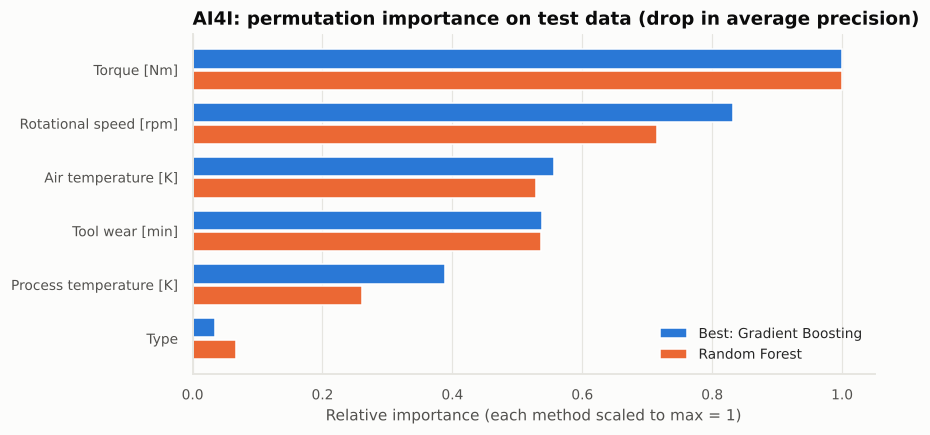

In [12]:
best_pipe = joblib.load(ROOT / best["model_file"])
perm = {}
for lab, pipe in [(f"Best: {name(best['algo'])}", best_pipe), ("Random Forest", models["rf"])]:
    if lab.endswith("Random Forest") and best["algo"] == "rf":
        continue
    perm[lab] = E.permutation(pipe, X_te, y_te, n_repeats=5, max_rows=None)
perm_df = pd.DataFrame({k: v["mean"] for k, v in perm.items()}).fillna(0)
for k, v in perm.items(): print(k); display(v.head(10).round(4))
V.save(V.importance_bars(perm_df.clip(lower=0) / perm_df.max(), f"{DS.upper()}: permutation importance on test data (drop in average precision)", top=15), FIGD / "19_permutation_importance.png"); plt.show()
pd.concat({**{"impurity_"+k: v for k, v in imp.items()}, **{"perm_"+k: v["mean"] for k, v in perm.items()}}, axis=1).to_csv(R / f"{DS}_feature_importance.csv")

SHAP model: Gradient Boosting | sample: 2000


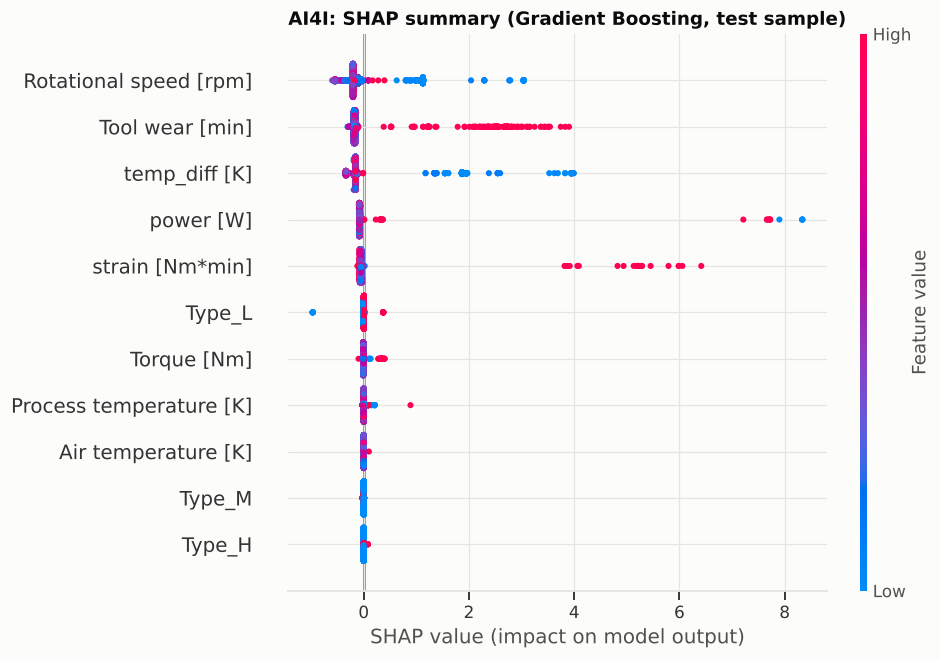

,mean |SHAP|
Rotational speed [rpm],0.3487
Tool wear [min],0.3473
temp_diff [K],0.3432
power [W],0.1367
strain [Nm*min],0.1154
Type_L,0.0144
Torque [Nm],0.0136
Process temperature [K],0.0051
Air temperature [K],0.0008
Type_M,0.0007


In [13]:
import shap
shap_algo = best["algo"] if best["algo"] in ("rf","gb","dtree") else "gb"
shap_pipe = joblib.load(C.MODELS_DIR / f"{DS}_{shap_algo}_tuned.joblib")
sample = X_te.sample(min(len(X_te), 2000), random_state=C.RANDOM_STATE)
sv, Xt = E.shap_values(shap_pipe, sample)
print("SHAP model:", name(shap_algo), "| sample:", len(sample))
plt.figure(); shap.summary_plot(sv, Xt, max_display=15, show=False, plot_size=(9, 6))
plt.title(f"{DS.upper()}: SHAP summary ({name(shap_algo)}, test sample)", loc="left", fontsize=12, fontweight="bold")
V.save(plt.gcf(), FIGD / "20_shap_summary.png"); plt.show()
ms = pd.Series(np.abs(sv).mean(0), index=Xt.columns).sort_values(ascending=False)
ms.to_csv(R / f"{DS}_shap_mean_abs.csv", header=["mean_abs_shap"]); display(ms.head(12).round(4).to_frame("mean |SHAP|"))

## 9. Selected model

In [14]:
print(json.dumps(best, indent=2))
display(tt[(tt.model == f"{best['algo']}_tuned")][show].round(4))

{
  "dataset": "ai4i",
  "algo": "gb",
  "strategy": "none",
  "params": {
    "clf__learning_rate": 0.01855998084649059,
    "clf__max_depth": 2,
    "clf__min_samples_leaf": 1,
    "clf__n_estimators": 500,
    "clf__subsample": 0.85
  },
  "threshold": 0.58,
  "model_file": "models/ai4i_gb_tuned.joblib",
  "criterion": "highest OOF F1 at the OOF-selected threshold (tie-break: OOF PR-AUC)"
}


,model,threshold_rule,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,fpr,fnr,fp,fn
13,gb_tuned,default_0.5,0.50,0.9935,1.0,0.8088,0.8943,0.9681,0.9045,0.0,0.1912,0,13
14,gb_tuned,oof_f1,0.58,0.9930,1.0,0.7941,0.8852,0.9681,0.9045,0.0,0.2059,0,14


## 10. Findings

**Model ranking (5-fold CV, OOF).** Gradient Boosting (PR-AUC 0.909) ≈ Random Forest (0.901)
≈ tuned Decision Tree (0.894) ≫ KNN (0.691) ≫ Logistic Regression (0.496). The three tree
models are within about one fold standard deviation of each other (≈0.02–0.03). The failure
modes are thresholds and interactions (ΔT *and* speed; torque × wear above a type-specific
limit), which axis-aligned splits capture directly and a linear model can't.

**Selected model:** tuned Gradient Boosting (500 shallow trees, depth 2, lr ≈ 0.019),
threshold 0.58 chosen on OOF F1. **Test set:** precision 1.000, recall 0.794, F1 0.885,
PR-AUC 0.905, ROC-AUC 0.968. That is 0 false alarms and 14 missed failures out of 68.

**Imbalance handling did not improve ranking quality.** For every algorithm, class weighting,
random oversampling and SMOTE kept or *lowered* OOF PR-AUC. They raise recall at the default
0.5 threshold at a large cost in precision (e.g. GB with class weights: recall 0.83 → 0.89,
precision 0.96 → 0.56). SMOTE hurt the most: interpolating between the few, rule-generated
failure points creates synthetic rows that don't follow the rules. Choosing the decision
threshold on OOF predictions achieves the same trade-off more transparently, so no tuned
model ended up using resampling.

**Where the recall ceiling comes from.** The best model catches 100% of power (PWF) and
overstrain (OSF) failures and 25/28 heat-dissipation failures, but **0/9 tool-wear failures**
and neither of the 2 failures with no subtype flagged. By construction, TWF happens at a
*random* tool-wear time between 200 and 240 min, and RNF is random. The sensors only say
the machine is *in* the risk window, not when the failure will happen. That is a property of
the data, not a modeling defect.

**Feature engineering matters most.** Adding ΔT, power and strain raised OOF PR-AUC from
0.782 → 0.909 (GB), 0.760 → 0.895 (RF) and 0.483 → 0.688 (untuned DT). SHAP, impurity and
permutation importance all point to the same drivers: rotational speed, tool wear, ΔT,
power and strain. Raw air and process temperature matter mainly through their difference.

**Caveat.** AI4I is synthetic, and its failure labels are deterministic rules on these same
quantities. High scores show that the models recover the generating rules; they are not
evidence of comparable performance on a real milling machine. All importances are
statistical associations inside this dataset, not causal effects.